In [36]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import tensorflow as tf
import cv2
from tensorflow.keras import models
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, ConfusionMatrixDisplay
from tensorflow.keras.applications import MobileNetV2

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("karapy/neurovision")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/karapy/neurovision


In [3]:
DATA = Path('/kaggle/input/datasets/karapy/neurovision/Data/')

In [4]:
SIZE = (224, 224)
EXTS = {'.jpeg', '.jpg', '.bmp', '.png'}
RANDOM_SEED = 42

In [5]:
# get classes names

arr_names = []
for folder in DATA.iterdir():
    arr_names.append(folder.name)

arr_names

['glioma', 'meningioma', 'notumor', 'pituitary']

In [6]:

def load_dataset(data_dir=DATA, arr_names=arr_names):

    imgs_path_str, labels = [], []

    for class_name in arr_names:

        image_path = data_dir / class_name

        for path in image_path.iterdir():

            if path.suffix.lower() not in EXTS:
                continue

            imgs_path_str.append(str(path))
            labels.append(class_name)

    return np.array(imgs_path_str), np.array(labels)


In [7]:
imgs_path, labels = load_dataset()

print(imgs_path.shape, labels.shape)
print(imgs_path[0])
print(labels[0])
print(np.unique(labels, return_counts=True))

(7023,) (7023,)
/kaggle/input/datasets/karapy/neurovision/Data/glioma/Te-glTr_0000.jpg
glioma
(array(['glioma', 'meningioma', 'notumor', 'pituitary'], dtype='<U10'), array([1621, 1645, 2000, 1757]))


In [8]:
le = LabelEncoder()
labels_int = le.fit_transform(labels)

print("Class mapping:", dict(enumerate(le.classes_)))
print(labels_int[:5])

Class mapping: {0: np.str_('glioma'), 1: np.str_('meningioma'), 2: np.str_('notumor'), 3: np.str_('pituitary')}
[0 0 0 0 0]


In [9]:
X_train, X_temp, y_train, y_temp = train_test_split( imgs_path, labels_int, 
                                                            test_size=0.2, 
                                                            stratify=labels_int, 
                                                            random_state=RANDOM_SEED )

X_val, X_test, y_val, y_test = train_test_split( X_temp, y_temp, 
                                                        test_size=0.5, 
                                                        stratify=y_temp, 
                                                        random_state=RANDOM_SEED )

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (5618,) (5618,)
Validation: (702,) (702,)
Test: (703,) (703,)


In [10]:
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))

I0000 00:00:1792588324.559058     476 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792588324.561281     476 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [11]:
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))

In [12]:
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))

In [13]:
# function to load images and normalize them 

def load_img(path, label):
    img = tf.io.read_file(path)
 
    img = tf.io.decode_image( img, 
                             channels=3, 
                             expand_animations=False )

    # resize the img
    img = tf.image.resize(img, SIZE)

    # normalize pixel values
    img = tf.keras.applications.mobilenet_v2.preprocess_input(img)

    return img, label

In [14]:
train_ds = train_ds.map(load_img).shuffle(len(X_train), seed=RANDOM_SEED).batch(32).prefetch(tf.data.AUTOTUNE)

In [15]:
val_ds = val_ds.map(load_img).batch(32).prefetch(tf.data.AUTOTUNE)

In [16]:
test_ds = test_ds.map(load_img).batch(32).prefetch(tf.data.AUTOTUNE)

## MobileNetV2

In [17]:

# Transfer Learning with MobileNetV2

base_model = MobileNetV2(weights='imagenet',
                         include_top=False,
                         input_shape=(224, 224, 3))

base_model.trainable = False

In [18]:
early_stop = tf.keras.callbacks.EarlyStopping( monitor="val_loss", 
                                              patience=3, 
                                              restore_best_weights=True )

In [19]:
checkpoint = tf.keras.callbacks.ModelCheckpoint('mobilenetv2_mri.keras', save_best_only=True)

In [20]:
mobile_model = models.Sequential()

In [21]:
mobile_model.add(base_model)
mobile_model.add(tf.keras.layers.GlobalAveragePooling2D())
mobile_model.add(tf.keras.layers.Dense(128, activation='relu'))
mobile_model.add(tf.keras.layers.Dropout(0.5))
mobile_model.add(tf.keras.layers.Dense(4, activation='softmax'))

In [22]:
mobile_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [23]:
mobile_model.compile(optimizer='adam', 
                     loss='sparse_categorical_crossentropy', 
                     metrics=['accuracy'])

In [24]:
mobile_history = mobile_model.fit( train_ds, 
                       epochs=10, 
                       validation_data=val_ds, 
                       verbose=2, callbacks=[early_stop, checkpoint] )

Epoch 1/10


2026-10-21 13:12:28.847334: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-21 13:12:28.984926: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1792588351.102370     519 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
2026-10-21 13:12:44.904032: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-21 13:12:45.063391: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-o

176/176 - 54s - 307ms/step - accuracy: 0.7857 - loss: 0.5535 - val_accuracy: 0.8775 - val_loss: 0.3540
Epoch 2/10
176/176 - 12s - 69ms/step - accuracy: 0.8838 - loss: 0.3183 - val_accuracy: 0.8789 - val_loss: 0.3111
Epoch 3/10
176/176 - 12s - 67ms/step - accuracy: 0.9021 - loss: 0.2573 - val_accuracy: 0.8903 - val_loss: 0.2825
Epoch 4/10
176/176 - 12s - 66ms/step - accuracy: 0.9217 - loss: 0.2206 - val_accuracy: 0.9103 - val_loss: 0.2522
Epoch 5/10
176/176 - 11s - 65ms/step - accuracy: 0.9219 - loss: 0.1967 - val_accuracy: 0.9145 - val_loss: 0.2114
Epoch 6/10
176/176 - 11s - 65ms/step - accuracy: 0.9315 - loss: 0.1783 - val_accuracy: 0.9131 - val_loss: 0.2149
Epoch 7/10
176/176 - 12s - 67ms/step - accuracy: 0.9423 - loss: 0.1537 - val_accuracy: 0.9274 - val_loss: 0.1871
Epoch 8/10
176/176 - 12s - 68ms/step - accuracy: 0.9484 - loss: 0.1382 - val_accuracy: 0.9288 - val_loss: 0.1775
Epoch 9/10
176/176 - 12s - 67ms/step - accuracy: 0.9539 - loss: 0.1267 - val_accuracy: 0.9373 - val_loss: 

In [25]:
mobile_pred = mobile_model.predict(test_ds)

21/22 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step

2026-10-21 13:15:04.452037: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-21 13:15:04.589333: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


22/22 ━━━━━━━━━━━━━━━━━━━━ 16s 562ms/step


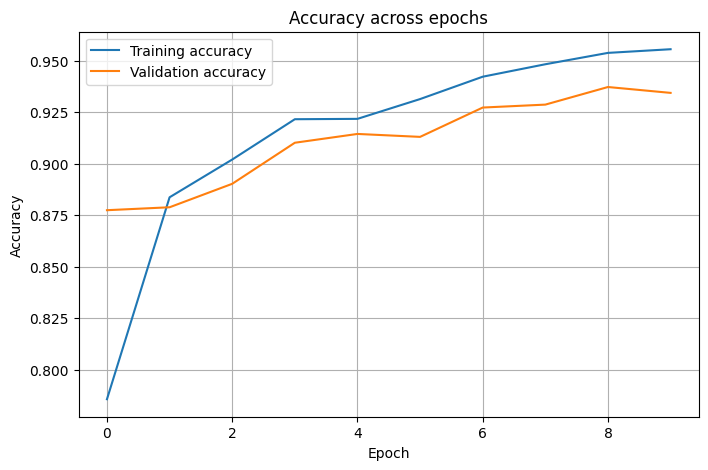

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(mobile_history.history['accuracy'], label='Training accuracy')
plt.plot(mobile_history.history['val_accuracy'], label='Validation accuracy')

plt.title('Accuracy across epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()


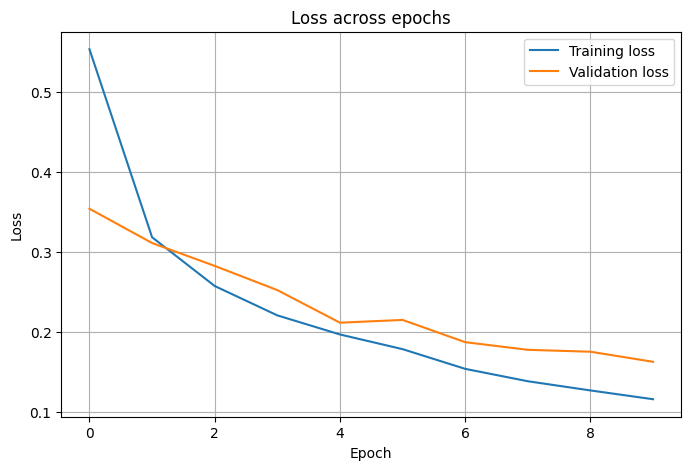

In [27]:

plt.figure(figsize=(8, 5))

plt.plot(mobile_history.history['loss'], label='Training loss')
plt.plot(mobile_history.history['val_loss'], label='Validation loss')

plt.title('Loss across epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

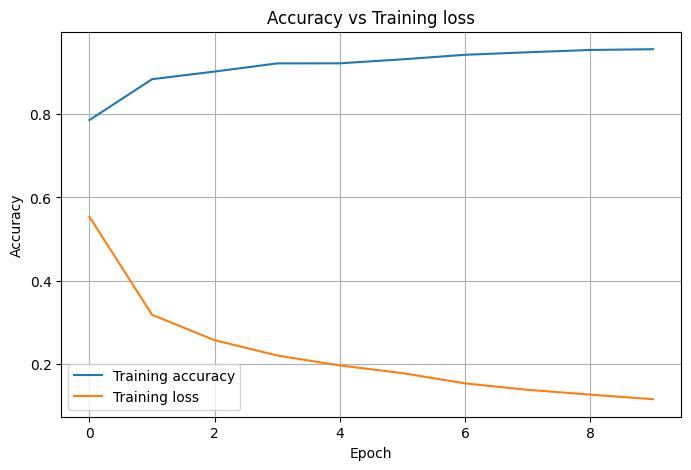

In [28]:

plt.figure(figsize=(8, 5))

plt.plot(mobile_history.history['accuracy'], label='Training accuracy')
plt.plot(mobile_history.history['loss'], label='Training loss')

plt.title('Accuracy vs Training loss')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show() 

In [30]:
test_loss, test_accuracy = mobile_model.evaluate(test_ds, verbose=2)

print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Test loss: {test_loss:.4f}")

22/22 - 4s - 170ms/step - accuracy: 0.9360 - loss: 0.1556
Test accuracy: 93.60%
Test loss: 0.1556


In [31]:
y_test[0]

np.int64(3)

In [32]:
model_pred = mobile_model.predict(test_ds)

22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step


In [33]:
pred_labels = np.argmax(model_pred, axis=1)

In [35]:
np.unique(pred_labels)

array([0, 1, 2, 3])

Text(0.5, 1.0, 'y_true : meningioma')

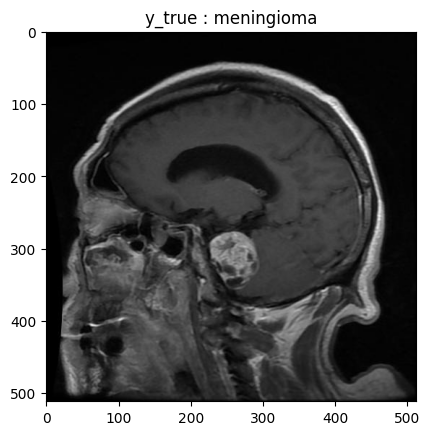

In [42]:
test_img = cv2.imread(X_test[5])
test_label = le.inverse_transform([y_test[5]])[0]
plt.imshow(test_img)
plt.title(f'y_true : {test_label}')

Text(0.5, 1.0, 'y_pred : meningioma')

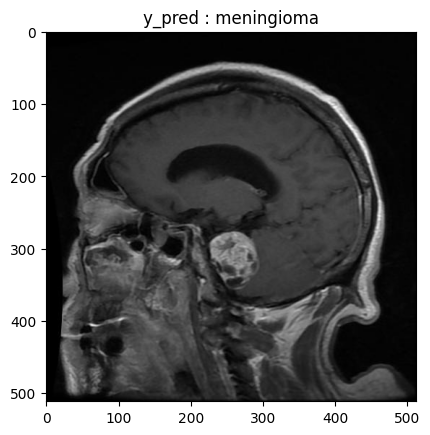

In [43]:
pred_label = le.inverse_transform([pred_labels[5]])[0]
plt.imshow(test_img)
plt.title(f'y_pred : {pred_label}')